In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))

from task3 import load_network, run_from_starting_players

A, P, player_ids = load_network()

print("Number of players:", len(player_ids))
print("Matrix dimensions:", P.shape)

Number of players: 1191
Matrix dimensions: (1191, 1191)


In [7]:
alphas = [0.50, 0.85, 0.95, 0.99]
n = len(player_ids)

pagerank_matrices = {}

for alpha in alphas:
    G = alpha * P + (1 - alpha) / n

    assert np.all(G > 0)
    assert np.allclose(G.sum(axis=1), 1)

    pagerank_matrices[alpha] = G
    print(f"PageRank matrix ready for alpha = {alpha}")

PageRank matrix ready for alpha = 0.5
PageRank matrix ready for alpha = 0.85
PageRank matrix ready for alpha = 0.95
PageRank matrix ready for alpha = 0.99


In [8]:
pagerank_results = {}

for alpha in alphas:
    G = pagerank_matrices[alpha]
    runs = run_from_starting_players(G, player_ids)
    pagerank_results[alpha] = runs

    for starting_player, result in runs.items():
        assert result.converged, "Iteration did not converge"
        assert np.allclose(result.final.sum(), 1)
        assert np.all(result.final > 0)
        assert np.abs(result.final @ G - result.final).sum() < 1e-10

        print(
            f"alpha = {alpha:.2f} | "
            f"start: {starting_player} | "
            f"iterations: {result.iterations}"
        )

alpha = 0.50 | start: Novak Djokovic | iterations: 17
alpha = 0.50 | start: Rohan Bopanna | iterations: 18
alpha = 0.85 | start: Novak Djokovic | iterations: 25
alpha = 0.85 | start: Rohan Bopanna | iterations: 28
alpha = 0.95 | start: Novak Djokovic | iterations: 27
alpha = 0.95 | start: Rohan Bopanna | iterations: 31
alpha = 0.99 | start: Novak Djokovic | iterations: 28
alpha = 0.99 | start: Rohan Bopanna | iterations: 33


In [9]:
import pandas as pd

iteration_table = pd.DataFrame(
    {
        alpha: {
            player: result.iterations
            for player, result in pagerank_results[alpha].items()
        }
        for alpha in alphas
    }
).T

iteration_table.index.name = "Alpha"
iteration_table.columns.name = "Starting player"

display(iteration_table)

Starting player,Novak Djokovic,Rohan Bopanna
Alpha,,
0.50,17,18
0.85,25,28
0.95,27,31
0.99,28,33


In [10]:
names_by_id = {i: name for name, i in player_ids.items()}
scores = pd.DataFrame(index=[names_by_id[i] for i in range(n)])
scores.index.name = "Player"

for alpha in alphas:
    runs = list(pagerank_results[alpha].values())

    # Check that both starting players lead to the same scores.
    gap = np.abs(runs[0].final - runs[1].final).sum()
    assert gap < 1e-9

    scores[alpha] = runs[0].final

top_players = scores[0.85].nlargest(10).index

print("PageRank scores (%)")
display((100 * scores.loc[top_players]).round(4))

PageRank scores (%)


,0.50,0.85,0.95,0.99
Player,,,,
Alexander Zverev,0.4067,0.8626,1.0588,1.1496
Taylor Fritz,0.4748,0.8379,0.9721,1.0316
Novak Djokovic,0.3943,0.8071,0.9873,1.0716
Daniil Medvedev,0.3740,0.7857,0.9645,1.0473
Andrey Rublev,0.3744,0.7794,0.9544,1.0356
Grigor Dimitrov,0.3889,0.7722,0.9309,1.0035
Karen Khachanov,0.3513,0.7265,0.8870,0.9610
Roberto Bautista Agut,0.3874,0.7091,0.8351,0.8918
Alex De Minaur,0.3509,0.6987,0.8455,0.9131


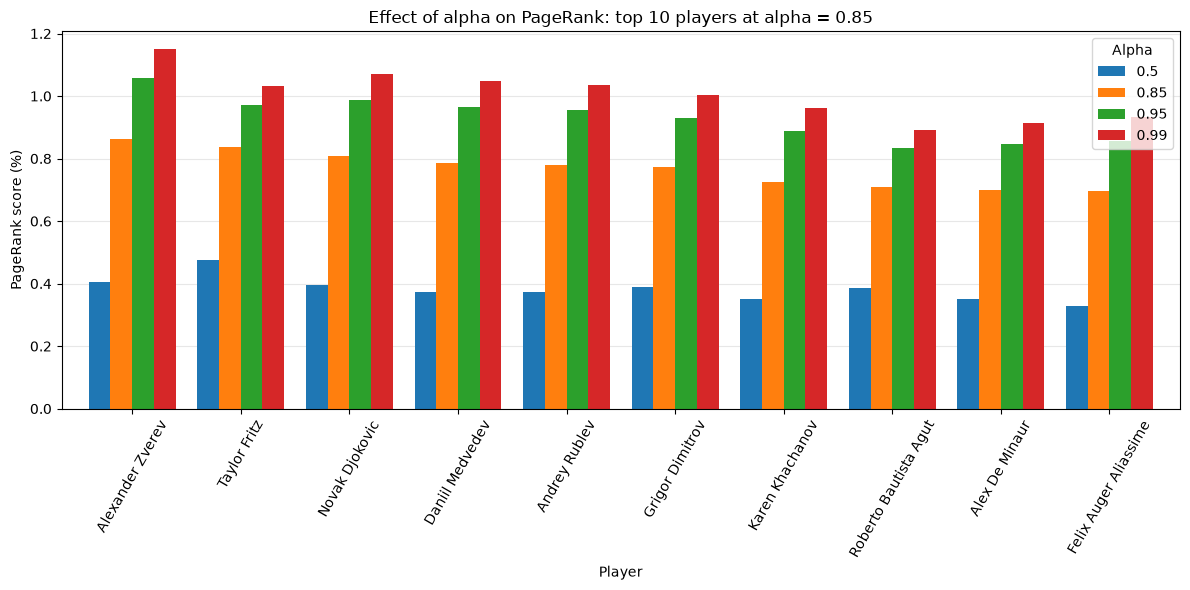

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))

(100 * scores.loc[top_players]).plot.bar(ax=ax, width=0.8)

ax.set_title("Effect of alpha on PageRank: top 10 players at alpha = 0.85")
ax.set_xlabel("Player")
ax.set_ylabel("PageRank score (%)")
ax.legend(title="Alpha")
ax.tick_params(axis="x", labelrotation=60)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

In [12]:
# Rank all 1,191 players for each alpha; 1 means highest score.
ranks = scores.rank(ascending=False, method="min").astype(int)

print("Ranking positions: 1 = highest")
display(ranks.loc[top_players])

print("Highest-ranked player for each alpha:")
for alpha in alphas:
    print(f"alpha = {alpha:.2f}: {scores[alpha].idxmax()}")

Ranking positions: 1 = highest


,0.50,0.85,0.95,0.99
Player,,,,
Alexander Zverev,2,1,1,1
Taylor Fritz,1,2,3,5
Novak Djokovic,4,3,2,2
Daniil Medvedev,9,4,4,3
Andrey Rublev,8,5,5,4
Grigor Dimitrov,5,6,6,6
Karen Khachanov,11,7,7,7
Roberto Bautista Agut,6,8,11,11
Alex De Minaur,12,9,9,10


Highest-ranked player for each alpha:
alpha = 0.50: Taylor Fritz
alpha = 0.85: Alexander Zverev
alpha = 0.95: Alexander Zverev
alpha = 0.99: Alexander Zverev


In [13]:
# Largest score minus smallest score across the four alpha values.
# Multiply by 100 to express the difference in percentage points.
score_changes = 100 * (scores.max(axis=1) - scores.min(axis=1))

sensitivity_table = pd.DataFrame({
    "Score range (percentage points)": score_changes
}).sort_values(
    "Score range (percentage points)", ascending=False
)

display(sensitivity_table.head(10).round(4))

,Score range (percentage points)
Player,
Alexander Zverev,0.7429
Novak Djokovic,0.6773
Daniil Medvedev,0.6732
Andrey Rublev,0.6612
Grigor Dimitrov,0.6146
Karen Khachanov,0.6097
Rafael Nadal,0.6071
Felix Auger Aliassime,0.6028
Stefanos Tsitsipas,0.6006


In [14]:
output_folder = Path.cwd() / "figures"
output_folder.mkdir(exist_ok=True)

fig.savefig(
    output_folder / "task7_alpha_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

iteration_table.to_csv(output_folder / "task7_iterations.csv")
scores.to_csv(output_folder / "task7_scores.csv")
ranks.to_csv(output_folder / "task7_ranks.csv")
sensitivity_table.to_csv(output_folder / "task7_sensitivity.csv")

print("Task 7 graph and tables saved in the figures folder.")

Task 7 graph and tables saved in the figures folder.
